# Used-car price prediction: exploratory data analysis

This notebook focuses only on exploratory analysis of the cleaned Car Price Assignment dataset (Data 3). It does not train models or create train/test splits. The cleaning step is reproducible in `src/preprocess_data3.py`.

In [26]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

In [27]:
def first_existing(paths):
    for path in paths:
        candidate = Path(path)
        if candidate.exists():
            return candidate
    raise FileNotFoundError("None of these dataset paths exists:\n" + "\n".join(map(str, paths)))


df_3_path = first_existing([
    "data/processed/data3_cleaned.csv",
    "../data/processed/data3_cleaned.csv",
    "/kaggle/input/datasets/mazenbassem/data3-cleaned/data3_cleaned.csv",
    "/kaggle/input/car-pricev3/data3_cleaned.csv",
])
df_3 = pd.read_csv(df_3_path)
print(f"Data 3 loaded from: {df_3_path}")
print(f"Rows: {len(df_3):,} | Columns: {df_3.shape[1]}")

Data 3 loaded from: /kaggle/input/datasets/mazenbassem/data3-cleaned/data3_cleaned.csv
Rows: 201 | Columns: 27


## 1. Dataset overview and quality checks

In [28]:
display(df_3.head())
print("Data types:")
display(df_3.dtypes.rename("dtype").to_frame())
print("Duplicate rows:", int(df_3.duplicated().sum()))
quality = pd.DataFrame({
    "dtype": df_3.dtypes.astype(str),
    "missing": df_3.isna().sum(),
    "missing_pct": (df_3.isna().mean() * 100).round(2),
    "unique_values": df_3.nunique(),
})
display(quality)
print("Summary statistics:")
display(df_3.describe(include="all").T)

,car_id,symboling,brand,model,fuel_type,aspiration,doors,body_style,drive_wheel,engine_location,...,engine_size,fuel_system,bore_ratio,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,1,3,alfa-romero,giulia,gas,std,two,convertible,rwd,front,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,2,3,alfa-romero,stelvio,gas,std,two,convertible,rwd,front,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,3,1,alfa-romero,quadrifoglio,gas,std,two,hatchback,rwd,front,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,4,2,audi,100 ls,gas,std,four,sedan,fwd,front,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,5,2,audi,100ls,gas,std,four,sedan,4wd,front,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


Data types:


,dtype
car_id,int64
symboling,int64
brand,object
model,object
fuel_type,object
aspiration,object
doors,object
body_style,object
drive_wheel,object
engine_location,object


Duplicate rows: 0


,dtype,missing,missing_pct,unique_values
car_id,int64,0,0.0,201
symboling,int64,0,0.0,6
brand,object,0,0.0,23
model,object,0,0.0,140
fuel_type,object,0,0.0,2
aspiration,object,0,0.0,2
doors,object,0,0.0,2
body_style,object,0,0.0,5
drive_wheel,object,0,0.0,3
engine_location,object,0,0.0,2


Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_id,201.0,NaN,NaN,NaN,103.900498,59.234956,1.0,54.0,104.0,155.0,205.0
symboling,201.0,NaN,NaN,NaN,0.840796,1.254802,-2.0,0.0,1.0,2.0,3.0
brand,201,23,toyota,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,201,140,corolla,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel_type,201,2,gas,181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspiration,201,2,std,165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
doors,201,2,four,114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body_style,201,5,sedan,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drive_wheel,201,3,fwd,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine_location,201,2,front,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Univariate distributions

The plots below show the shape, spread, and possible skew of the numerical variables.

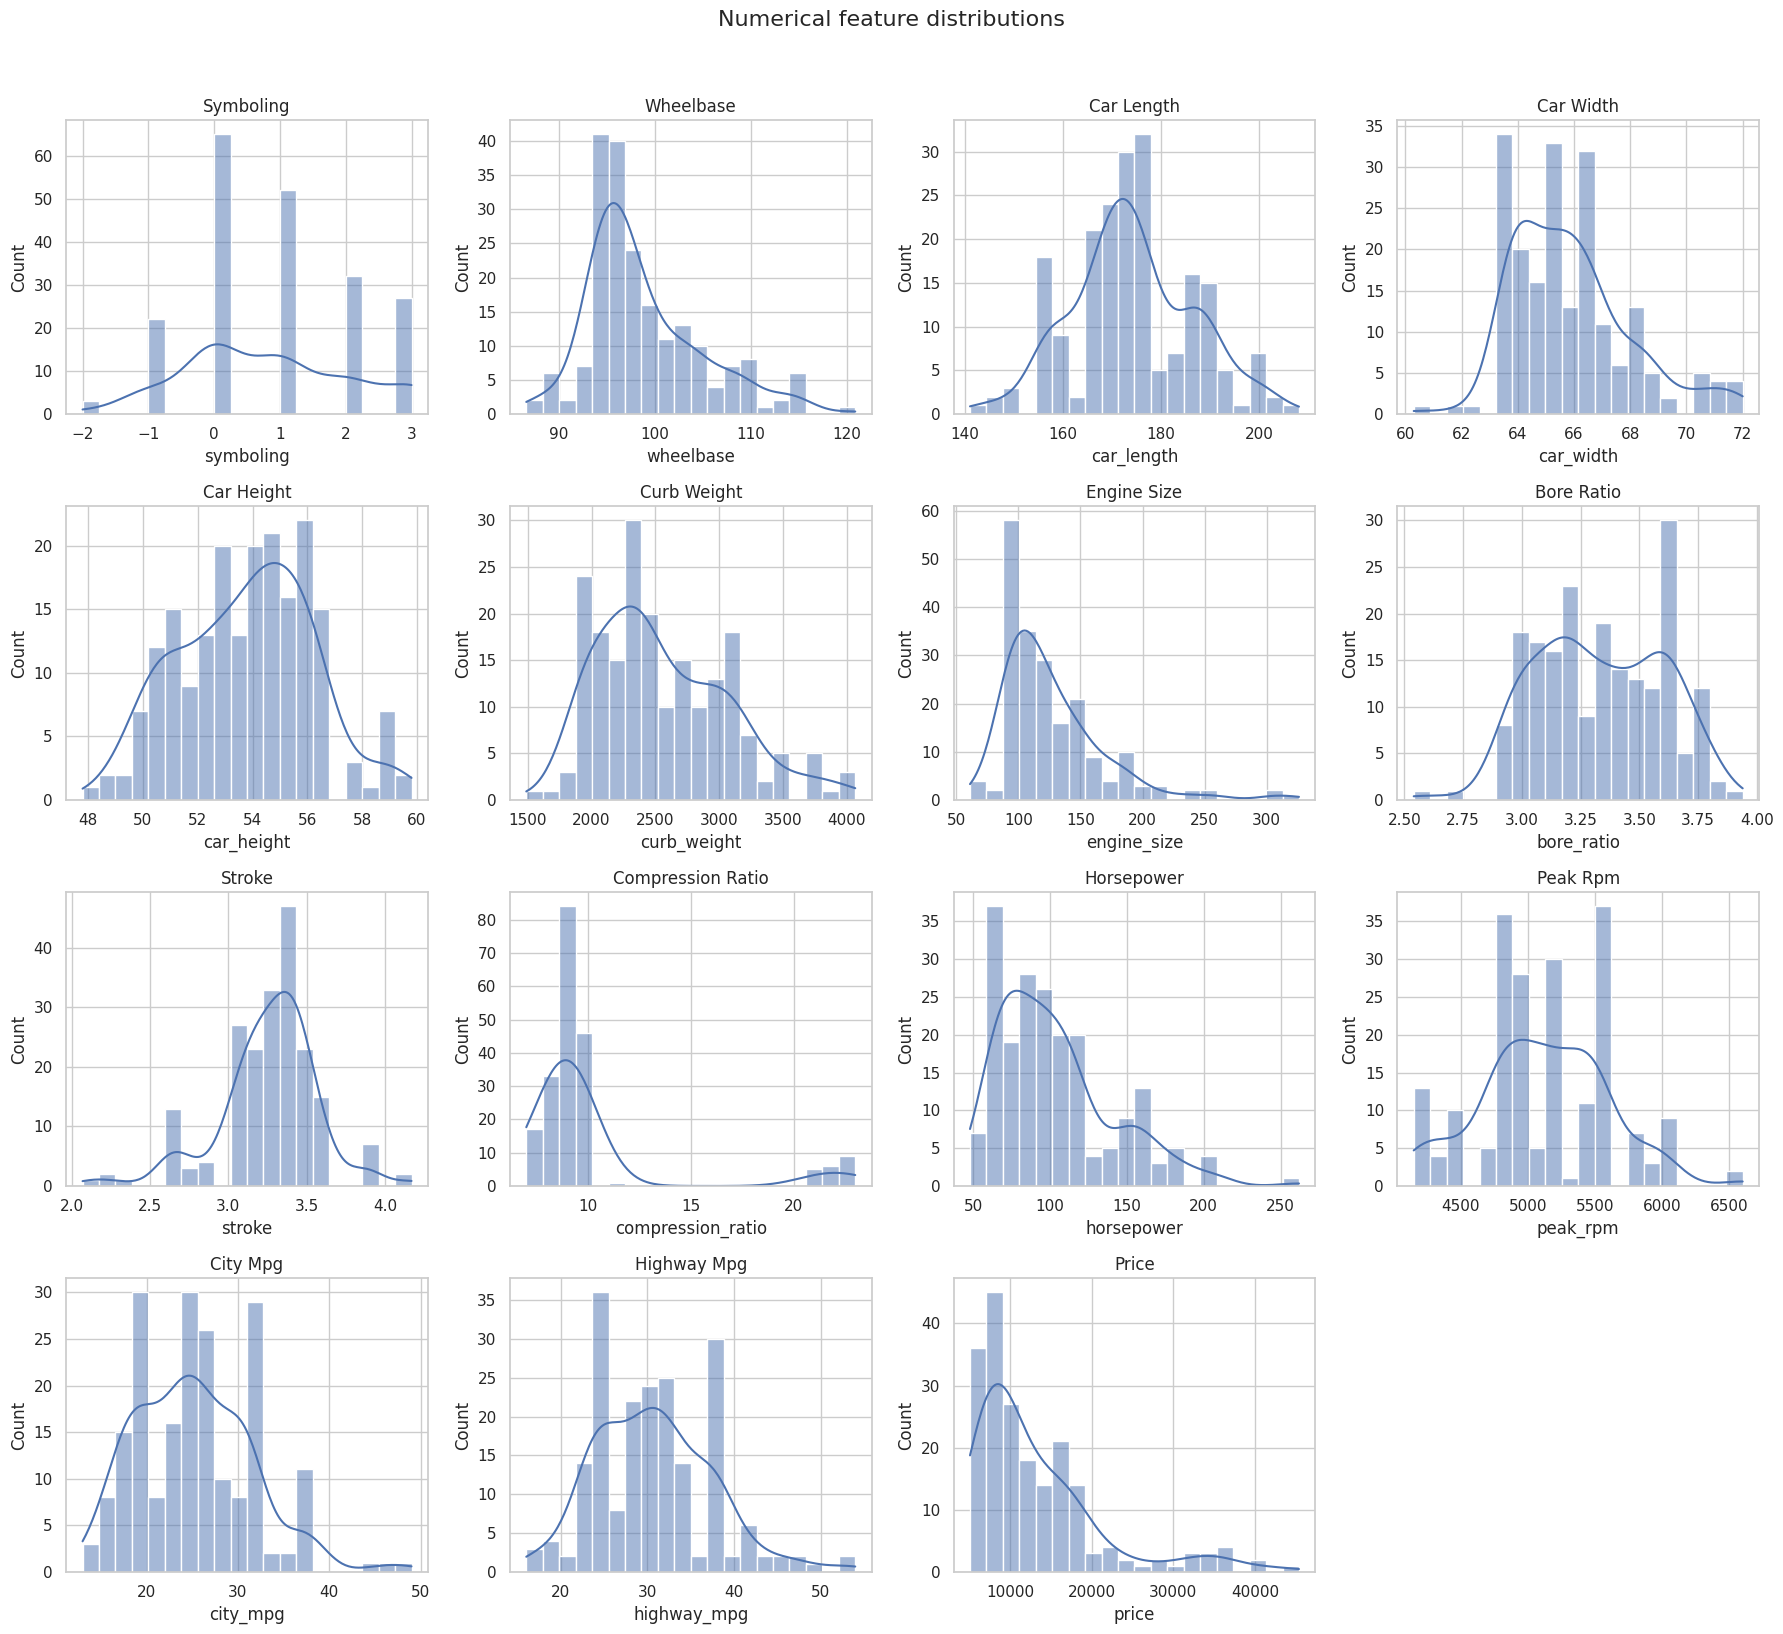

In [29]:
numeric_columns = df_3.select_dtypes(include=np.number).columns.tolist()
numeric_columns.remove("car_id")

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
for ax, column in zip(axes.flat, numeric_columns):
    sns.histplot(df_3[column], kde=True, bins=20, ax=ax)
    ax.set_title(column.replace("_", " ").title())
for ax in axes.flat[len(numeric_columns):]:
    ax.remove()
fig.suptitle("Numerical feature distributions", y=1.02, fontsize=16)
plt.tight_layout()

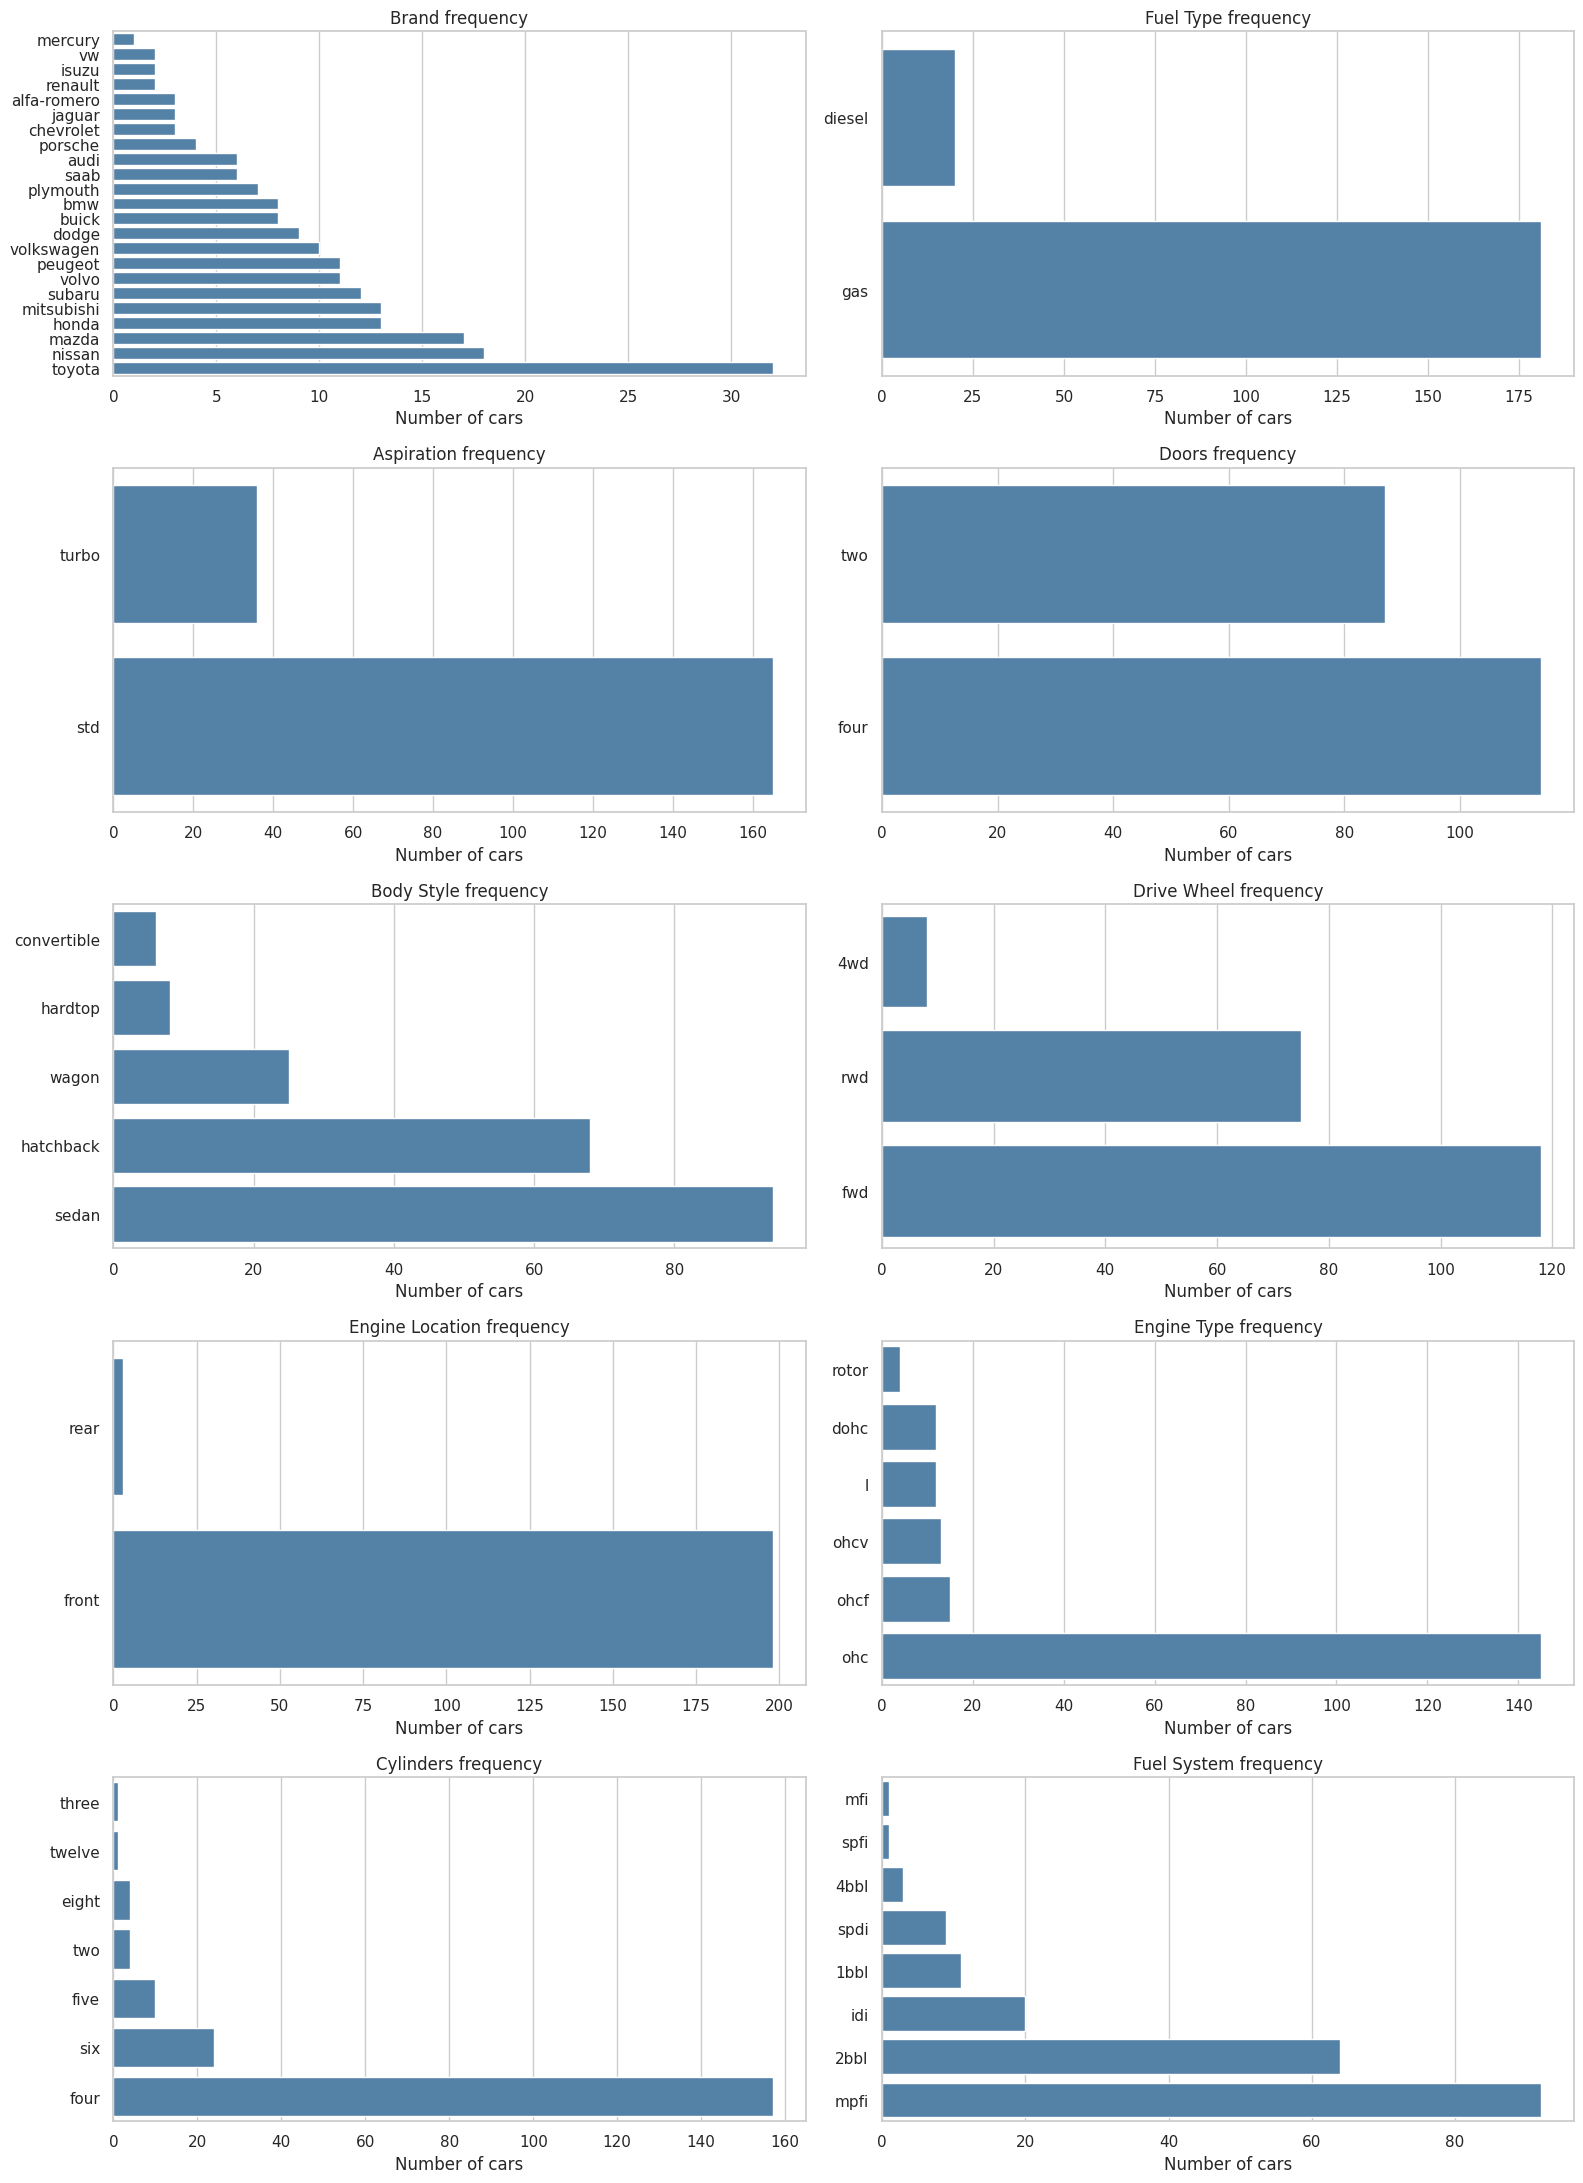

In [30]:
categorical_columns = [
    "brand", "fuel_type", "aspiration", "doors", "body_style", "drive_wheel",
    "engine_location", "engine_type", "cylinders", "fuel_system",
]

fig, axes = plt.subplots(5, 2, figsize=(16, 22))
for ax, column in zip(axes.flat, categorical_columns):
    counts = df_3[column].value_counts().sort_values()
    sns.barplot(x=counts.values, y=counts.index, ax=ax, color="steelblue")
    ax.set_title(f"{column.replace('_', ' ').title()} frequency")
    ax.set_xlabel("Number of cars")
    ax.set_ylabel("")
plt.tight_layout()

## 3. Price analysis

Price is the target variable for the later modeling stage, but here it is examined descriptively only.

,price
count,201.000000
mean,13207.129353
std,7947.066342
min,5118.000000
25%,7775.000000
50%,10295.000000
75%,16500.000000
max,45400.000000


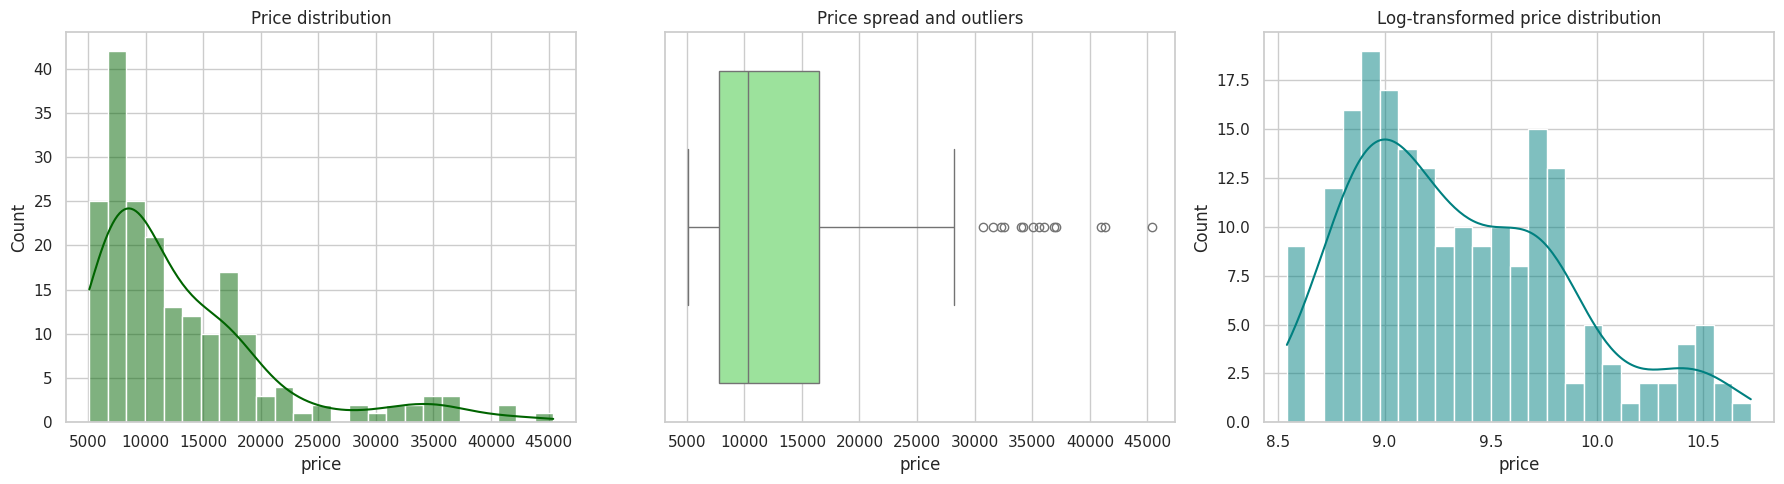

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df_3["price"], kde=True, bins=25, ax=axes[0], color="darkgreen")
axes[0].set_title("Price distribution")
sns.boxplot(x=df_3["price"], ax=axes[1], color="lightgreen")
axes[1].set_title("Price spread and outliers")
sns.histplot(np.log1p(df_3["price"]), kde=True, bins=25, ax=axes[2], color="teal")
axes[2].set_title("Log-transformed price distribution")
plt.tight_layout()

display(df_3["price"].describe().to_frame("price"))

,body_style,car_count,median_price,mean_price,min_price,max_price
1,hardtop,8,19687.5,22208.500000,8249,45400
0,convertible,6,17084.5,21890.500000,11595,37028
4,wagon,25,11694.0,12371.960000,6918,28248
3,sedan,94,11078.5,14459.755319,5499,41315
2,hatchback,68,8672.0,9957.441176,5118,22018


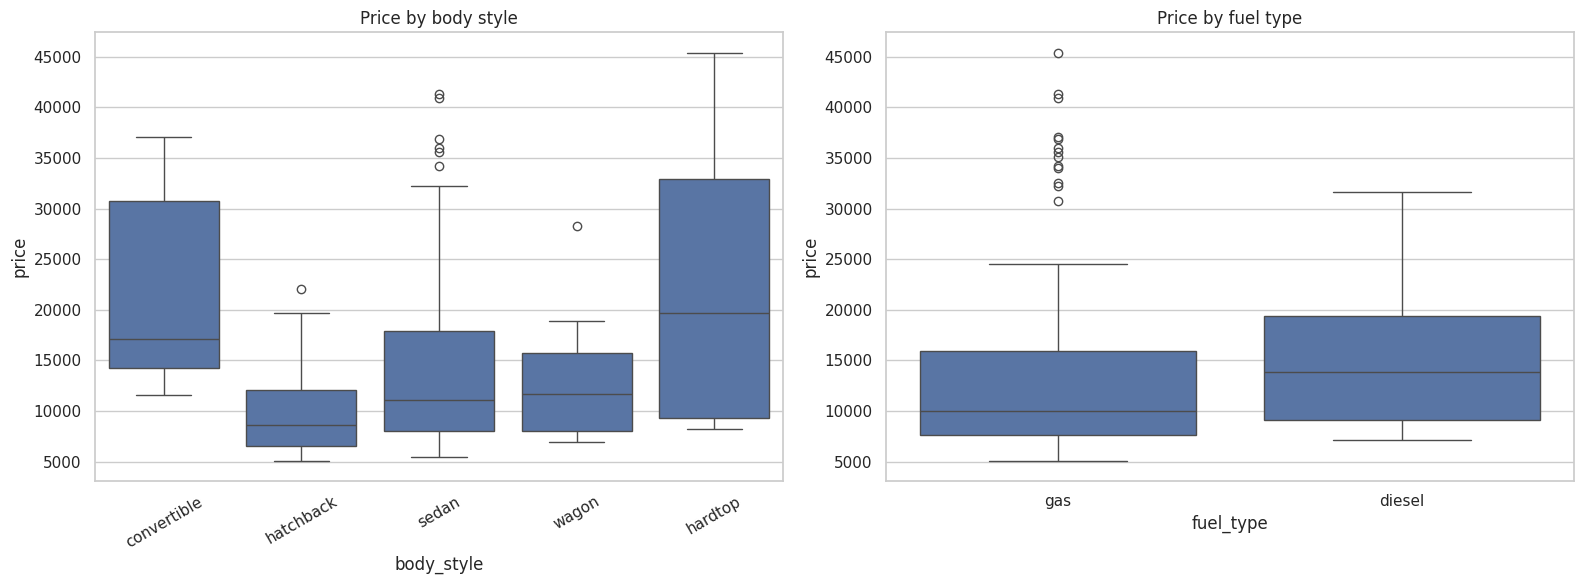

In [32]:
grouped_price = (
    df_3.groupby("body_style", as_index=False)
    .agg(car_count=("price", "size"), median_price=("price", "median"),
         mean_price=("price", "mean"), min_price=("price", "min"), max_price=("price", "max"))
    .sort_values("median_price", ascending=False)
)
display(grouped_price)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df_3, x="body_style", y="price", ax=axes[0])
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_title("Price by body style")
sns.boxplot(data=df_3, x="fuel_type", y="price", ax=axes[1])
axes[1].set_title("Price by fuel type")
plt.tight_layout()

,brand,car_count,median_price,mean_price
8,jaguar,3,35550.0,34600.000000
15,porsche,4,33278.0,31400.500000
3,buick,8,32892.0,33647.000000
2,bmw,8,22835.0,26118.750000
21,volvo,11,18420.0,18063.181818
1,audi,6,17580.0,17859.166667
13,peugeot,11,16630.0,15489.090909
0,alfa-romero,3,16500.0,15498.333333
17,saab,6,15275.0,15223.333333
9,mazda,17,10595.0,10652.882353


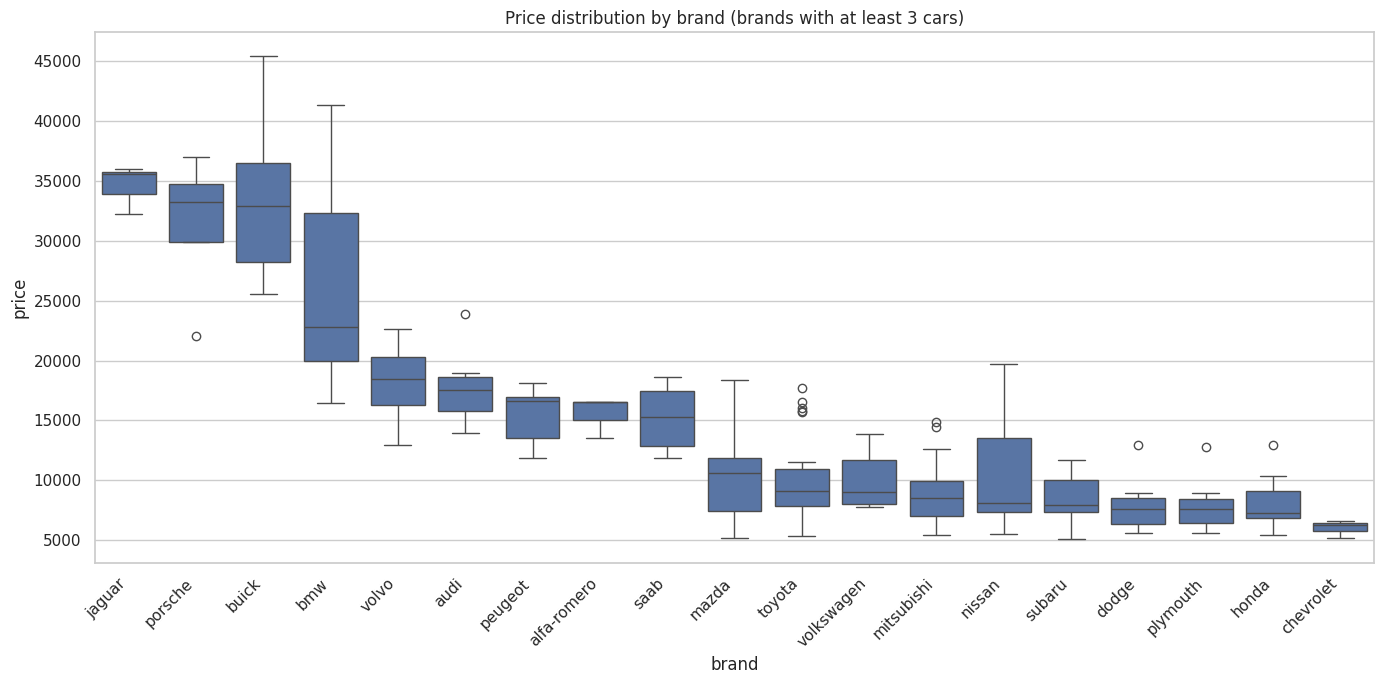

In [33]:
top_brands = (
    df_3.groupby("brand", as_index=False)
    .agg(car_count=("price", "size"), median_price=("price", "median"), mean_price=("price", "mean"))
    .query("car_count >= 3")
    .sort_values("median_price", ascending=False)
)
display(top_brands)

plt.figure(figsize=(14, 7))
sns.boxplot(data=df_3, x="brand", y="price", order=top_brands["brand"])
plt.xticks(rotation=45, ha="right")
plt.title("Price distribution by brand (brands with at least 3 cars)")
plt.tight_layout()

## 4. Relationships between numerical variables

,correlation_with_price
price,1.000000
engine_size,0.872335
curb_weight,0.834415
horsepower,0.810795
car_width,0.751265
wheelbase,0.584642
compression_ratio,0.071107
city_mpg,-0.686571
highway_mpg,-0.704692


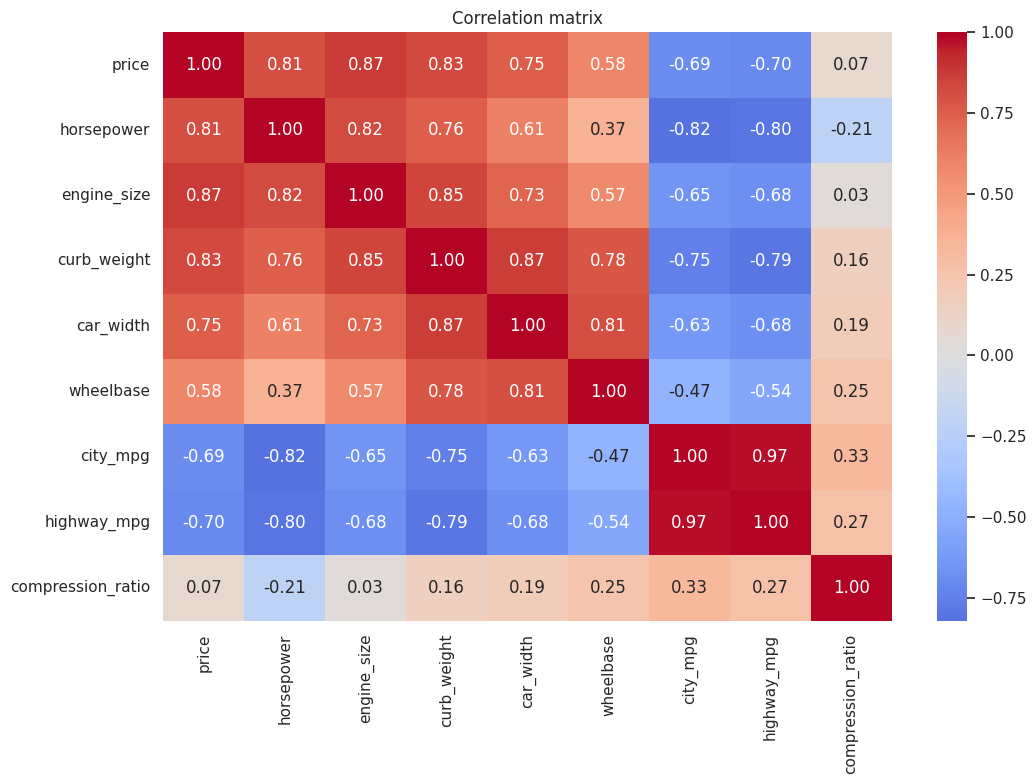

In [34]:
relationship_columns = [
    "price", "horsepower", "engine_size", "curb_weight", "car_width",
    "wheelbase", "city_mpg", "highway_mpg", "compression_ratio",
]
correlations = df_3[relationship_columns].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()

display(correlations["price"].sort_values(ascending=False).to_frame("correlation_with_price"))

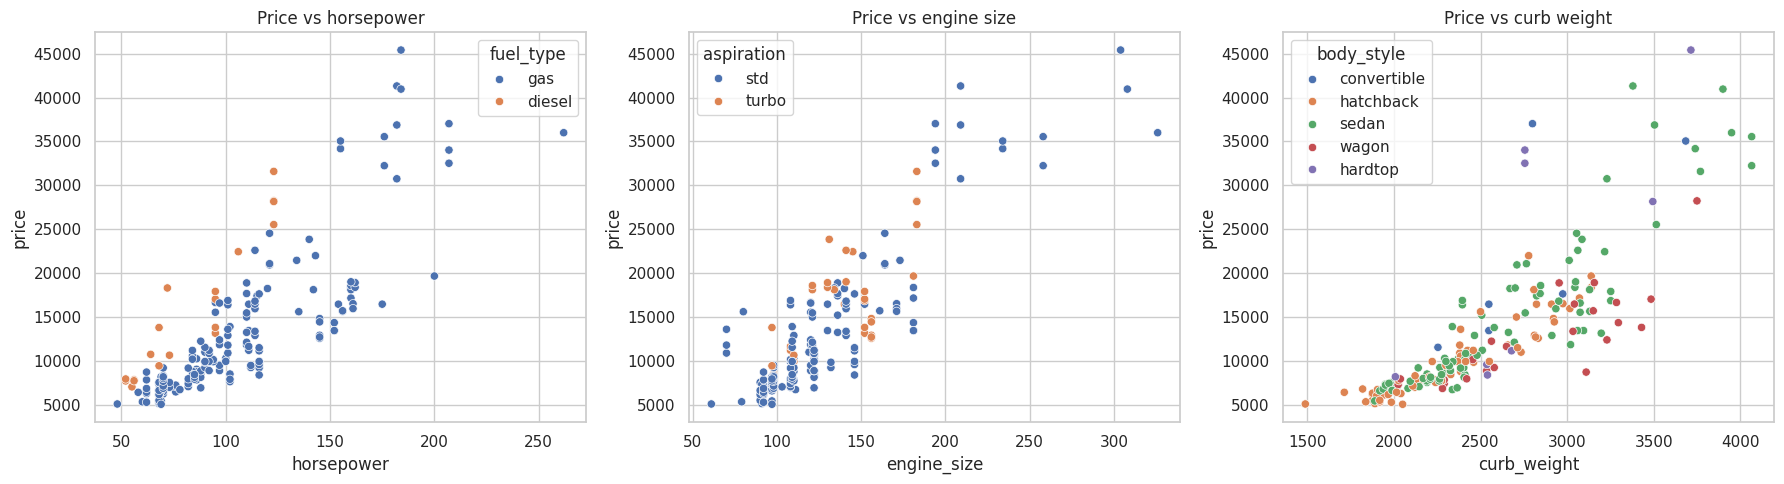

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df_3, x="horsepower", y="price", hue="fuel_type", ax=axes[0])
axes[0].set_title("Price vs horsepower")
sns.scatterplot(data=df_3, x="engine_size", y="price", hue="aspiration", ax=axes[1])
axes[1].set_title("Price vs engine size")
sns.scatterplot(data=df_3, x="curb_weight", y="price", hue="body_style", ax=axes[2])
axes[2].set_title("Price vs curb weight")
plt.tight_layout()

## 5. Segment comparisons and observations

These summaries support hypotheses for later modeling; they are descriptive and do not establish causation.

In [36]:
segment_summary = (
    df_3.groupby(["drive_wheel", "aspiration"], as_index=False)
    .agg(car_count=("price", "size"), median_price=("price", "median"),
         median_horsepower=("horsepower", "median"), median_mpg=("highway_mpg", "median"))
    .sort_values("median_price", ascending=False)
)
display(segment_summary)

print("Highest-priced observations:")
display(df_3.nlargest(10, "price")[["brand", "model", "body_style", "horsepower", "engine_size", "price"]])
print("Lowest-priced observations:")
display(df_3.nsmallest(10, "price")[["brand", "model", "body_style", "horsepower", "engine_size", "price"]])

,drive_wheel,aspiration,car_count,median_price,median_horsepower,median_mpg
5,rwd,turbo,18,18685.0,123.0,25.0
4,rwd,std,57,16515.0,116.0,25.0
3,fwd,turbo,16,11663.5,116.0,30.0
1,4wd,turbo,2,11476.5,111.0,26.0
0,4wd,std,6,8395.5,77.5,30.0
2,fwd,std,102,7896.5,76.0,34.0


Highest-priced observations:


,brand,model,body_style,horsepower,engine_size,price
71,buick,regal sport coupe (turbo),hardtop,184,304,45400
15,bmw,x5,sedan,182,209,41315
70,buick,century special,sedan,184,308,40960
125,porsche,boxter,convertible,207,194,37028
16,bmw,x3,sedan,182,209,36880
46,jaguar,xk,sedan,262,326,36000
45,jaguar,xf,sedan,176,258,35550
69,buick,skylark,convertible,155,234,35056
68,buick,opel isuzu deluxe,sedan,155,234,34184
124,porsche,cayenne,hardtop,207,194,34028


Lowest-priced observations:


,brand,model,body_style,horsepower,engine_size,price
134,subaru,unknown,hatchback,69,97,5118
17,chevrolet,impala,hatchback,48,61,5151
47,mazda,rx3,hatchback,68,91,5195
146,toyota,corona mark ii,hatchback,62,92,5348
73,mitsubishi,mirage,hatchback,68,92,5389
31,honda,civic,hatchback,60,79,5399
86,nissan,versa,sedan,69,97,5499
20,dodge,rampage,hatchback,68,90,5572
115,plymouth,fury iii,hatchback,68,90,5572
48,mazda,glc deluxe,hatchback,68,91,6095


## EDA takeaways

- Review the displayed missing-value table before feature engineering.
- Compare medians as well as means because vehicle prices are typically skewed.
- Interpret correlations as associations; brand, body style, and engine characteristics may interact.
- The next notebook stage can use these findings to define features and modeling questions, but no model is trained here.